<a href="https://colab.research.google.com/github/192565033simats-png/machine_learning/blob/main/Machine_Learning_Lab.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
# EXP-1
import pandas as pd

# Training dataset
data = {
    'Sky': ['Sunny', 'Sunny', 'Rainy', 'Sunny'],
    'AirTemp': ['Warm', 'Warm', 'Cold', 'Warm'],
    'Humidity': ['Normal', 'High', 'High', 'High'],
    'Wind': ['Strong', 'Strong', 'Strong', 'Weak'],
    'Water': ['Warm', 'Warm', 'Warm', 'Cool'],
    'Forecast': ['Same', 'Same', 'Change', 'Change'],
    'EnjoySport': ['Yes', 'Yes', 'No', 'Yes']
}

df = pd.DataFrame(data)

print("Training Data:")
print(df)

# FIND-S Algorithm
hypothesis = ['0'] * (len(df.columns) - 1)

for i in range(len(df)):
    if df.iloc[i, -1] == 'Yes':
        for j in range(len(hypothesis)):

            if hypothesis[j] == '0':
                hypothesis[j] = df.iloc[i, j]

            elif hypothesis[j] != df.iloc[i, j]:
                hypothesis[j] = '?'

print("\nMost Specific Hypothesis:")
print(hypothesis)

Training Data:
     Sky AirTemp Humidity    Wind Water Forecast EnjoySport
0  Sunny    Warm   Normal  Strong  Warm     Same        Yes
1  Sunny    Warm     High  Strong  Warm     Same        Yes
2  Rainy    Cold     High  Strong  Warm   Change         No
3  Sunny    Warm     High    Weak  Cool   Change        Yes

Most Specific Hypothesis:
['Sunny', 'Warm', '?', '?', '?', '?']


In [ ]:
# EXP-2
import pandas as pd

# ---------------------------------------------------
# STEP 1: Create Training Dataset
# ---------------------------------------------------

data = {
    'Sky': ['Sunny', 'Sunny', 'Rainy', 'Sunny'],
    'AirTemp': ['Warm', 'Warm', 'Cold', 'Warm'],
    'Humidity': ['Normal', 'High', 'High', 'High'],
    'Wind': ['Strong', 'Strong', 'Strong', 'Weak'],
    'Water': ['Warm', 'Warm', 'Warm', 'Cool'],
    'Forecast': ['Same', 'Same', 'Change', 'Change'],
    'EnjoySport': ['Yes', 'Yes', 'No', 'Yes']
}

df = pd.DataFrame(data)

# Save dataset as CSV
df.to_csv('training_data.csv', index=False)

print("Training data saved as training_data.csv")
print("\nTraining Data:")
print(df)


# ---------------------------------------------------
# STEP 2: Read CSV File
# ---------------------------------------------------

data = pd.read_csv('training_data.csv')

X = data.iloc[:, :-1].values
Y = data.iloc[:, -1].values

attributes = list(data.columns[:-1])
n = len(attributes)


# ---------------------------------------------------
# STEP 3: Initialize S and G
# ---------------------------------------------------

# Most Specific Hypothesis
S = ['0'] * n

# Most General Hypothesis
G = [['?'] * n]


# ---------------------------------------------------
# STEP 4: Candidate-Elimination Algorithm
# ---------------------------------------------------

for i in range(len(X)):

    example = X[i]
    label = Y[i]

    print("\n----------------------------------------")
    print("Example", i + 1, ":", list(example), "=>", label)

    # -----------------------------------------------
    # POSITIVE EXAMPLE
    # -----------------------------------------------
    if label == 'Yes':

        # Remove hypotheses from G that do not cover
        # the positive example
        G = [
            g for g in G
            if all(g[j] == '?' or g[j] == example[j]
                   for j in range(n))
        ]

        # Generalize S
        for j in range(n):

            if S[j] == '0':
                S[j] = example[j]

            elif S[j] != example[j]:
                S[j] = '?'

    # -----------------------------------------------
    # NEGATIVE EXAMPLE
    # -----------------------------------------------
    else:

        new_G = []

        for g in G:

            # Check whether G covers the negative example
            covers_negative = all(
                g[j] == '?' or g[j] == example[j]
                for j in range(n)
            )

            if covers_negative:

                # Specialize G using S
                for j in range(n):

                    if S[j] != '0' and S[j] != '?' \
                            and S[j] != example[j]:

                        new_g = g.copy()
                        new_g[j] = S[j]

                        # Keep only hypotheses consistent
                        # with S
                        if new_g not in new_G:
                            new_G.append(new_g)

            else:
                new_G.append(g)

        G = new_G

    print("Specific Boundary (S):")
    print(S)

    print("General Boundary (G):")
    for g in G:
        print(g)


# ---------------------------------------------------
# STEP 5: Final Result
# ---------------------------------------------------

print("\n========================================")
print("FINAL RESULT")
print("========================================")

print("\nMost Specific Hypothesis (S):")
print(S)

print("\nSet of General Hypotheses (G):")
for g in G:
    print(g)

Training data saved as training_data.csv

Training Data:
     Sky AirTemp Humidity    Wind Water Forecast EnjoySport
0  Sunny    Warm   Normal  Strong  Warm     Same        Yes
1  Sunny    Warm     High  Strong  Warm     Same        Yes
2  Rainy    Cold     High  Strong  Warm   Change         No
3  Sunny    Warm     High    Weak  Cool   Change        Yes

----------------------------------------
Example 1 : ['Sunny', 'Warm', 'Normal', 'Strong', 'Warm', 'Same'] => Yes
Specific Boundary (S):
['Sunny', 'Warm', 'Normal', 'Strong', 'Warm', 'Same']
General Boundary (G):
['?', '?', '?', '?', '?', '?']

----------------------------------------
Example 2 : ['Sunny', 'Warm', 'High', 'Strong', 'Warm', 'Same'] => Yes
Specific Boundary (S):
['Sunny', 'Warm', '?', 'Strong', 'Warm', 'Same']
General Boundary (G):
['?', '?', '?', '?', '?', '?']

----------------------------------------
Example 3 : ['Rainy', 'Cold', 'High', 'Strong', 'Warm', 'Change'] => No
Specific Boundary (S):
['Sunny', 'Warm', '?', 

Training Dataset:
     Outlook Temperature Humidity    Wind PlayTennis
0      Sunny         Hot     High    Weak         No
1      Sunny         Hot     High  Strong         No
2   Overcast         Hot     High    Weak        Yes
3       Rain        Mild     High    Weak        Yes
4       Rain        Cool   Normal    Weak        Yes
5       Rain        Cool   Normal  Strong         No
6   Overcast        Cool   Normal  Strong        Yes
7      Sunny        Mild     High    Weak         No
8      Sunny        Cool   Normal    Weak        Yes
9       Rain        Mild   Normal    Weak        Yes
10     Sunny        Mild   Normal  Strong        Yes
11  Overcast        Mild     High  Strong        Yes
12  Overcast         Hot   Normal    Weak        Yes
13      Rain        Mild     High  Strong         No


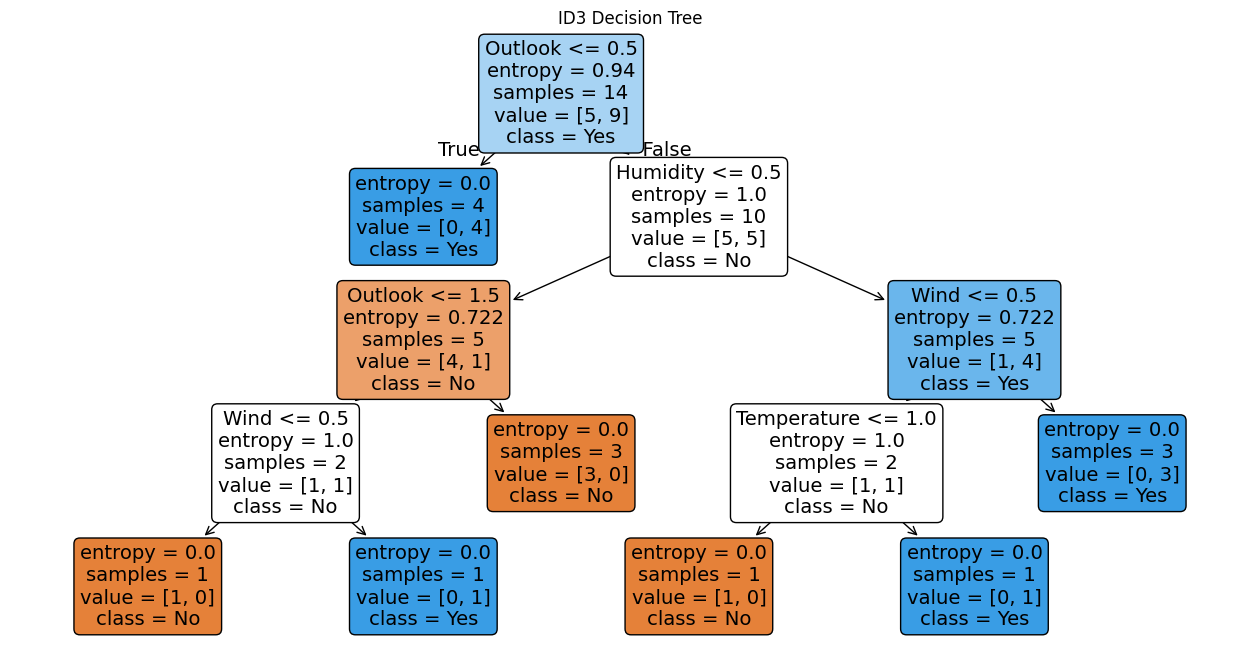


Training Accuracy:
1.0

New Sample:
Outlook = Sunny
Temperature = Cool
Humidity = High
Wind = Strong

Predicted Result:
No


In [ ]:
# ---------------------------------------------------
# 3. ID3 DECISION TREE ALGORITHM
# ---------------------------------------------------

import pandas as pd
import matplotlib.pyplot as plt

from sklearn.preprocessing import LabelEncoder
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.metrics import accuracy_score


# ---------------------------------------------------
# STEP 1: Create Dataset
# ---------------------------------------------------

data = {
    'Outlook': [
        'Sunny', 'Sunny', 'Overcast', 'Rain',
        'Rain', 'Rain', 'Overcast', 'Sunny',
        'Sunny', 'Rain', 'Sunny', 'Overcast',
        'Overcast', 'Rain'
    ],

    'Temperature': [
        'Hot', 'Hot', 'Hot', 'Mild',
        'Cool', 'Cool', 'Cool', 'Mild',
        'Cool', 'Mild', 'Mild', 'Mild',
        'Hot', 'Mild'
    ],

    'Humidity': [
        'High', 'High', 'High', 'High',
        'Normal', 'Normal', 'Normal', 'High',
        'Normal', 'Normal', 'Normal', 'High',
        'Normal', 'High'
    ],

    'Wind': [
        'Weak', 'Strong', 'Weak', 'Weak',
        'Weak', 'Strong', 'Strong', 'Weak',
        'Weak', 'Weak', 'Strong', 'Strong',
        'Weak', 'Strong'
    ],

    'PlayTennis': [
        'No', 'No', 'Yes', 'Yes',
        'Yes', 'No', 'Yes', 'No',
        'Yes', 'Yes', 'Yes', 'Yes',
        'Yes', 'No'
    ]
}

df = pd.DataFrame(data)

print("Training Dataset:")
print(df)


# ---------------------------------------------------
# STEP 2: Convert Categorical Data into Numbers
# ---------------------------------------------------

encoders = {}

for column in df.columns:

    encoder = LabelEncoder()

    df[column] = encoder.fit_transform(df[column])

    encoders[column] = encoder


# Features and target
X = df.drop('PlayTennis', axis=1)
y = df['PlayTennis']


# ---------------------------------------------------
# STEP 3: Create ID3 Decision Tree
# ---------------------------------------------------

model = DecisionTreeClassifier(
    criterion='entropy',
    random_state=42
)

model.fit(X, y)


# ---------------------------------------------------
# STEP 4: Display Decision Tree
# ---------------------------------------------------

plt.figure(figsize=(16, 8))

plot_tree(
    model,
    feature_names=X.columns,
    class_names=['No', 'Yes'],
    filled=True,
    rounded=True
)

plt.title("ID3 Decision Tree")
plt.show()


# ---------------------------------------------------
# STEP 5: Test the Model
# ---------------------------------------------------

y_pred = model.predict(X)

accuracy = accuracy_score(y, y_pred)

print("\nTraining Accuracy:")
print(accuracy)


# ---------------------------------------------------
# STEP 6: Classify a New Sample
# ---------------------------------------------------

# New sample:
# Outlook = Sunny
# Temperature = Cool
# Humidity = High
# Wind = Strong

new_sample = pd.DataFrame({
    'Outlook': [
        encoders['Outlook'].transform(['Sunny'])[0]
    ],

    'Temperature': [
        encoders['Temperature'].transform(['Cool'])[0]
    ],

    'Humidity': [
        encoders['Humidity'].transform(['High'])[0]
    ],

    'Wind': [
        encoders['Wind'].transform(['Strong'])[0]
    ]
})


# Prediction
prediction = model.predict(new_sample)


# Convert prediction back to Yes/No
result = encoders['PlayTennis'].inverse_transform(prediction)


print("\nNew Sample:")
print("Outlook = Sunny")
print("Temperature = Cool")
print("Humidity = High")
print("Wind = Strong")

print("\nPredicted Result:")
print(result[0])

XOR Predictions:
----------------
[0 0] => 0.0277 => Predicted: 0 Actual: 0
[0 1] => 0.9855 => Predicted: 1 Actual: 1
[1 0] => 0.9747 => Predicted: 1 Actual: 1
[1 1] => 0.0207 => Predicted: 0 Actual: 0


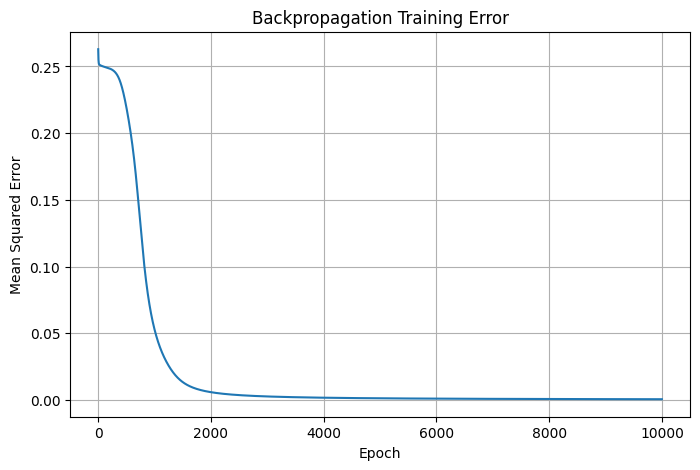

In [ ]:
# ---------------------------------------------------
# 4. ARTIFICIAL NEURAL NETWORK USING BACKPROPAGATION
# ---------------------------------------------------

import numpy as np
import matplotlib.pyplot as plt


# ---------------------------------------------------
# STEP 1: Create XOR Dataset
# ---------------------------------------------------

X = np.array([
    [0, 0],
    [0, 1],
    [1, 0],
    [1, 1]
])

y = np.array([
    [0],
    [1],
    [1],
    [0]
])


# ---------------------------------------------------
# STEP 2: Activation Function
# ---------------------------------------------------

def sigmoid(x):
    return 1 / (1 + np.exp(-x))


def sigmoid_derivative(x):
    return x * (1 - x)


# ---------------------------------------------------
# STEP 3: Initialize Weights
# ---------------------------------------------------

np.random.seed(42)

# Input layer -> Hidden layer
W1 = np.random.uniform(-1, 1, (2, 4))

# Hidden layer -> Output layer
W2 = np.random.uniform(-1, 1, (4, 1))

learning_rate = 0.5

errors = []


# ---------------------------------------------------
# STEP 4: Backpropagation Training
# ---------------------------------------------------

for epoch in range(10000):

    # -------------------------------
    # Forward Propagation
    # -------------------------------

    hidden_input = np.dot(X, W1)

    hidden_output = sigmoid(hidden_input)

    output_input = np.dot(hidden_output, W2)

    output = sigmoid(output_input)


    # -------------------------------
    # Calculate Error
    # -------------------------------

    error = y - output

    mse = np.mean(error ** 2)

    errors.append(mse)


    # -------------------------------
    # Backpropagation
    # -------------------------------

    output_delta = error * sigmoid_derivative(output)

    hidden_error = output_delta.dot(W2.T)

    hidden_delta = hidden_error * sigmoid_derivative(hidden_output)


    # -------------------------------
    # Update Weights
    # -------------------------------

    W2 += hidden_output.T.dot(output_delta) * learning_rate

    W1 += X.T.dot(hidden_delta) * learning_rate


# ---------------------------------------------------
# STEP 5: Display Results
# ---------------------------------------------------

print("XOR Predictions:")
print("----------------")

for i in range(len(X)):

    prediction = output[i][0]

    if prediction >= 0.5:
        result = 1
    else:
        result = 0

    print(
        X[i],
        "=>",
        round(prediction, 4),
        "=> Predicted:",
        result,
        "Actual:",
        y[i][0]
    )


# ---------------------------------------------------
# STEP 6: Plot Training Error
# ---------------------------------------------------

plt.figure(figsize=(8, 5))

plt.plot(errors)

plt.xlabel("Epoch")
plt.ylabel("Mean Squared Error")

plt.title("Backpropagation Training Error")

plt.grid(True)

plt.show()

K value: 5
Accuracy: 0.8

Actual vs Predicted:
--------------------
Actual: versicolor  | Predicted: versicolor
Actual: setosa  | Predicted: setosa
Actual: virginica  | Predicted: virginica
Actual: versicolor  | Predicted: versicolor
Actual: versicolor  | Predicted: versicolor
Actual: setosa  | Predicted: setosa
Actual: versicolor  | Predicted: versicolor
Actual: virginica  | Predicted: virginica
Actual: versicolor  | Predicted: versicolor
Actual: versicolor  | Predicted: virginica
Actual: virginica  | Predicted: virginica
Actual: setosa  | Predicted: setosa
Actual: setosa  | Predicted: setosa
Actual: setosa  | Predicted: setosa
Actual: setosa  | Predicted: setosa
Actual: versicolor  | Predicted: virginica
Actual: virginica  | Predicted: virginica
Actual: versicolor  | Predicted: versicolor
Actual: versicolor  | Predicted: virginica
Actual: virginica  | Predicted: virginica
Actual: setosa  | Predicted: setosa
Actual: virginica  | Predicted: versicolor
Actual: setosa  | Predicted: setos

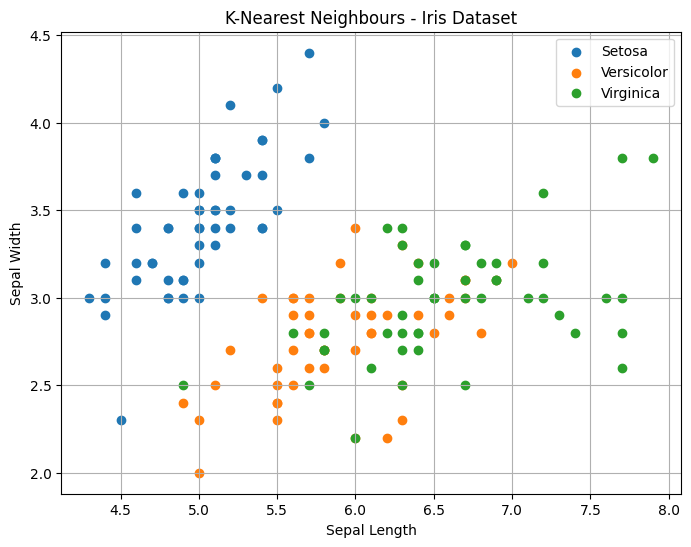

In [ ]:
# ---------------------------------------------------
# 5. K-NEAREST NEIGHBOURS (K-NN)
# ---------------------------------------------------

import numpy as np
import matplotlib.pyplot as plt

from sklearn.datasets import load_iris
from sklearn.model_selection import train_test_split
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import accuracy_score


# ---------------------------------------------------
# STEP 1: Load Iris Dataset
# ---------------------------------------------------

iris = load_iris()

X = iris.data[:, :2]   # First two features
y = iris.target


# ---------------------------------------------------
# STEP 2: Split Dataset
# ---------------------------------------------------

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42
)


# ---------------------------------------------------
# STEP 3: Create K-NN Model
# ---------------------------------------------------

k = 5

model = KNeighborsClassifier(n_neighbors=k)


# ---------------------------------------------------
# STEP 4: Train the Model
# ---------------------------------------------------

model.fit(X_train, y_train)


# ---------------------------------------------------
# STEP 5: Make Predictions
# ---------------------------------------------------

y_pred = model.predict(X_test)


# ---------------------------------------------------
# STEP 6: Calculate Accuracy
# ---------------------------------------------------

accuracy = accuracy_score(y_test, y_pred)

print("K value:", k)

print("Accuracy:",
      accuracy)


# ---------------------------------------------------
# STEP 7: Display Predictions
# ---------------------------------------------------

print("\nActual vs Predicted:")
print("--------------------")

for i in range(len(y_test)):

    actual = iris.target_names[y_test[i]]
    predicted = iris.target_names[y_pred[i]]

    print(
        "Actual:",
        actual,
        " | Predicted:",
        predicted
    )


# ---------------------------------------------------
# STEP 8: Plot Dataset
# ---------------------------------------------------

plt.figure(figsize=(8, 6))

plt.scatter(
    X[y == 0, 0],
    X[y == 0, 1],
    label="Setosa"
)

plt.scatter(
    X[y == 1, 0],
    X[y == 1, 1],
    label="Versicolor"
)

plt.scatter(
    X[y == 2, 0],
    X[y == 2, 1],
    label="Virginica"
)

plt.xlabel("Sepal Length")
plt.ylabel("Sepal Width")

plt.title("K-Nearest Neighbours - Iris Dataset")

plt.legend()

plt.grid(True)

plt.show()

Naive Bayes Classification
--------------------------

Accuracy:
1.0

Confusion Matrix:
[[10  0  0]
 [ 0  9  0]
 [ 0  0 11]]


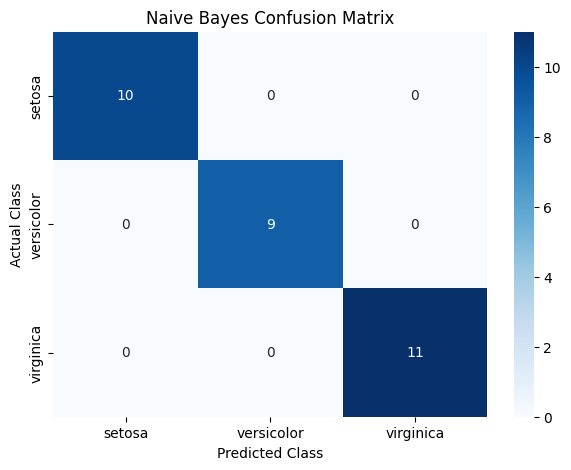

In [ ]:
# ---------------------------------------------------
# 6. NAIVE BAYES CLASSIFICATION
# ---------------------------------------------------

import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.datasets import load_iris
from sklearn.model_selection import train_test_split
from sklearn.naive_bayes import GaussianNB
from sklearn.metrics import accuracy_score, confusion_matrix


# ---------------------------------------------------
# STEP 1: Load Iris Dataset
# ---------------------------------------------------

iris = load_iris()

X = iris.data
y = iris.target


# ---------------------------------------------------
# STEP 2: Split Dataset
# ---------------------------------------------------

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42
)


# ---------------------------------------------------
# STEP 3: Create Naive Bayes Model
# ---------------------------------------------------

model = GaussianNB()


# ---------------------------------------------------
# STEP 4: Train Model
# ---------------------------------------------------

model.fit(X_train, y_train)


# ---------------------------------------------------
# STEP 5: Make Predictions
# ---------------------------------------------------

y_pred = model.predict(X_test)


# ---------------------------------------------------
# STEP 6: Calculate Accuracy
# ---------------------------------------------------

accuracy = accuracy_score(y_test, y_pred)

print("Naive Bayes Classification")
print("--------------------------")

print("\nAccuracy:")
print(accuracy)


# ---------------------------------------------------
# STEP 7: Confusion Matrix
# ---------------------------------------------------

cm = confusion_matrix(y_test, y_pred)

print("\nConfusion Matrix:")
print(cm)


# ---------------------------------------------------
# STEP 8: Display Confusion Matrix as Graph
# ---------------------------------------------------

plt.figure(figsize=(7, 5))

sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=iris.target_names,
    yticklabels=iris.target_names
)

plt.xlabel("Predicted Class")
plt.ylabel("Actual Class")

plt.title("Naive Bayes Confusion Matrix")

plt.show()

Logistic Regression
-------------------

Accuracy:
0.9

Confusion Matrix:
[[10  0  0]
 [ 0  7  2]
 [ 0  1 10]]


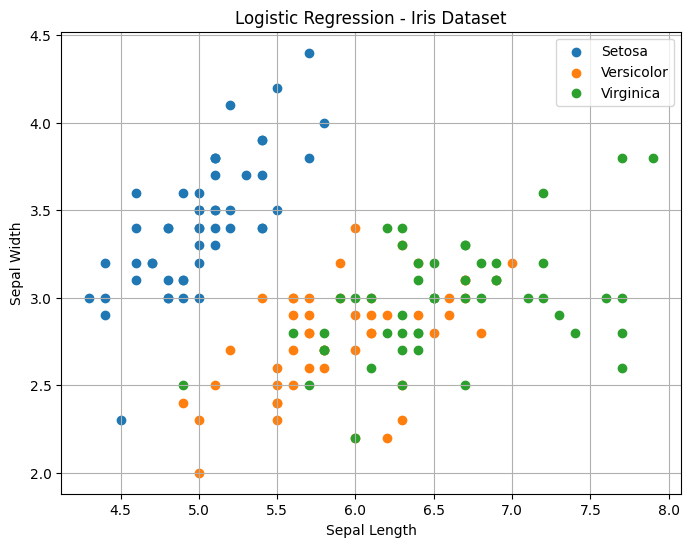

In [ ]:
# ---------------------------------------------------
# 7. LOGISTIC REGRESSION
# ---------------------------------------------------

import matplotlib.pyplot as plt

from sklearn.datasets import load_iris
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, confusion_matrix


# ---------------------------------------------------
# STEP 1: Load Iris Dataset
# ---------------------------------------------------

iris = load_iris()

# Use first two features for easy visualization
X = iris.data[:, :2]

y = iris.target


# ---------------------------------------------------
# STEP 2: Split Dataset
# ---------------------------------------------------

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42
)


# ---------------------------------------------------
# STEP 3: Create Logistic Regression Model
# ---------------------------------------------------

model = LogisticRegression(
    max_iter=200
)


# ---------------------------------------------------
# STEP 4: Train the Model
# ---------------------------------------------------

model.fit(X_train, y_train)


# ---------------------------------------------------
# STEP 5: Make Predictions
# ---------------------------------------------------

y_pred = model.predict(X_test)


# ---------------------------------------------------
# STEP 6: Calculate Accuracy
# ---------------------------------------------------

accuracy = accuracy_score(y_test, y_pred)

print("Logistic Regression")
print("-------------------")

print("\nAccuracy:")
print(accuracy)


# ---------------------------------------------------
# STEP 7: Display Confusion Matrix
# ---------------------------------------------------

cm = confusion_matrix(y_test, y_pred)

print("\nConfusion Matrix:")
print(cm)


# ---------------------------------------------------
# STEP 8: Plot Dataset
# ---------------------------------------------------

plt.figure(figsize=(8, 6))

plt.scatter(
    X[y == 0, 0],
    X[y == 0, 1],
    label="Setosa"
)

plt.scatter(
    X[y == 1, 0],
    X[y == 1, 1],
    label="Versicolor"
)

plt.scatter(
    X[y == 2, 0],
    X[y == 2, 1],
    label="Virginica"
)

plt.xlabel("Sepal Length")
plt.ylabel("Sepal Width")

plt.title("Logistic Regression - Iris Dataset")

plt.legend()

plt.grid(True)

plt.show()

Linear Regression
------------------

Actual Values:
[200  70]

Predicted Values:
[200.  70.]

Mean Squared Error:
4.0389678347315804e-28

R2 Score:
1.0

For a house of 1500 sq.ft:
Predicted Price = 150.0 lakhs


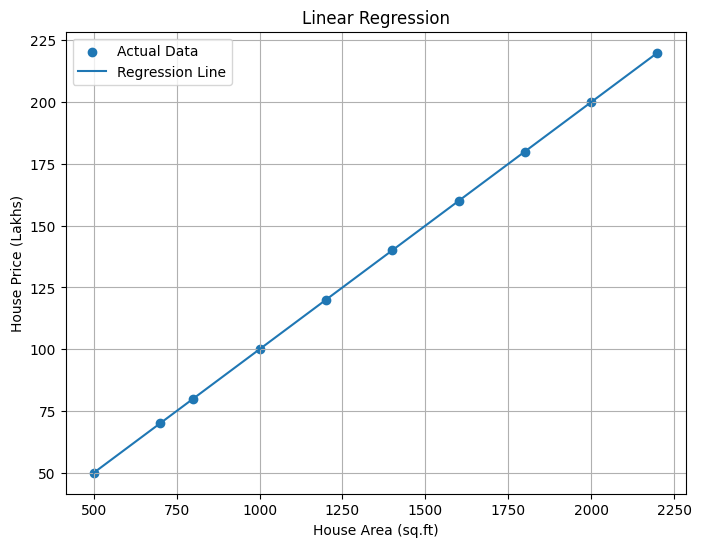

In [ ]:
# ---------------------------------------------------
# 8. LINEAR REGRESSION
# ---------------------------------------------------

import numpy as np
import matplotlib.pyplot as plt

from sklearn.linear_model import LinearRegression
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_squared_error, r2_score


# ---------------------------------------------------
# STEP 1: Create Dataset
# ---------------------------------------------------

# House area in square feet
X = np.array([
    [500],
    [700],
    [800],
    [1000],
    [1200],
    [1400],
    [1600],
    [1800],
    [2000],
    [2200]
])

# House price in lakhs
y = np.array([
    50,
    70,
    80,
    100,
    120,
    140,
    160,
    180,
    200,
    220
])


# ---------------------------------------------------
# STEP 2: Split Dataset
# ---------------------------------------------------

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42
)


# ---------------------------------------------------
# STEP 3: Create Linear Regression Model
# ---------------------------------------------------

model = LinearRegression()


# ---------------------------------------------------
# STEP 4: Train the Model
# ---------------------------------------------------

model.fit(X_train, y_train)


# ---------------------------------------------------
# STEP 5: Make Predictions
# ---------------------------------------------------

y_pred = model.predict(X_test)


# ---------------------------------------------------
# STEP 6: Display Results
# ---------------------------------------------------

print("Linear Regression")
print("------------------")

print("\nActual Values:")
print(y_test)

print("\nPredicted Values:")
print(y_pred)


# ---------------------------------------------------
# STEP 7: Calculate Performance
# ---------------------------------------------------

mse = mean_squared_error(y_test, y_pred)

r2 = r2_score(y_test, y_pred)

print("\nMean Squared Error:")
print(mse)

print("\nR2 Score:")
print(r2)


# ---------------------------------------------------
# STEP 8: Predict Price for New House
# ---------------------------------------------------

new_house = np.array([[1500]])

predicted_price = model.predict(new_house)

print("\nFor a house of 1500 sq.ft:")
print("Predicted Price =",
      round(predicted_price[0], 2),
      "lakhs")


# ---------------------------------------------------
# STEP 9: Plot Regression Line
# ---------------------------------------------------

plt.figure(figsize=(8, 6))

# Actual data
plt.scatter(
    X,
    y,
    label="Actual Data"
)

# Regression line
plt.plot(
    X,
    model.predict(X),
    label="Regression Line"
)

plt.xlabel("House Area (sq.ft)")
plt.ylabel("House Price (Lakhs)")

plt.title("Linear Regression")

plt.legend()

plt.grid(True)

plt.show()

LINEAR VS POLYNOMIAL REGRESSION
--------------------------------

Linear Regression:
MSE = 52.8
R2 Score = 0.9498

Polynomial Regression:
Degree = 2
MSE = 0.0
R2 Score = 1.0

Polynomial Regression performs better.


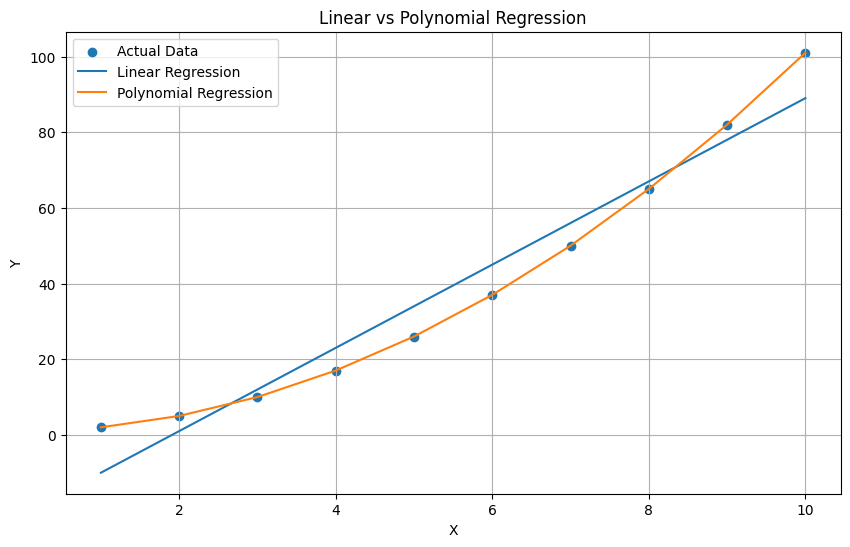

In [ ]:
# ---------------------------------------------------
# 9. LINEAR vs POLYNOMIAL REGRESSION
# ---------------------------------------------------

import numpy as np
import matplotlib.pyplot as plt

from sklearn.linear_model import LinearRegression
from sklearn.preprocessing import PolynomialFeatures
from sklearn.metrics import mean_squared_error, r2_score


# ---------------------------------------------------
# STEP 1: Create Dataset
# ---------------------------------------------------

X = np.array([
    [1],
    [2],
    [3],
    [4],
    [5],
    [6],
    [7],
    [8],
    [9],
    [10]
])

y = np.array([
    2,
    5,
    10,
    17,
    26,
    37,
    50,
    65,
    82,
    101
])


# ---------------------------------------------------
# STEP 2: Linear Regression
# ---------------------------------------------------

linear_model = LinearRegression()

linear_model.fit(X, y)

linear_pred = linear_model.predict(X)


# ---------------------------------------------------
# STEP 3: Polynomial Regression
# ---------------------------------------------------

# Degree of polynomial
degree = 2

poly = PolynomialFeatures(degree=degree)

X_poly = poly.fit_transform(X)

poly_model = LinearRegression()

poly_model.fit(X_poly, y)

poly_pred = poly_model.predict(X_poly)


# ---------------------------------------------------
# STEP 4: Calculate Errors
# ---------------------------------------------------

linear_mse = mean_squared_error(y, linear_pred)

poly_mse = mean_squared_error(y, poly_pred)

linear_r2 = r2_score(y, linear_pred)

poly_r2 = r2_score(y, poly_pred)


# ---------------------------------------------------
# STEP 5: Display Results
# ---------------------------------------------------

print("LINEAR VS POLYNOMIAL REGRESSION")
print("--------------------------------")

print("\nLinear Regression:")
print("MSE =", round(linear_mse, 4))
print("R2 Score =", round(linear_r2, 4))

print("\nPolynomial Regression:")
print("Degree =", degree)
print("MSE =", round(poly_mse, 4))
print("R2 Score =", round(poly_r2, 4))


# ---------------------------------------------------
# STEP 6: Compare Models
# ---------------------------------------------------

if poly_mse < linear_mse:
    print("\nPolynomial Regression performs better.")

else:
    print("\nLinear Regression performs better.")


# ---------------------------------------------------
# STEP 7: Plot Comparison
# ---------------------------------------------------

plt.figure(figsize=(10, 6))

# Actual data
plt.scatter(
    X,
    y,
    label="Actual Data"
)

# Linear regression line
plt.plot(
    X,
    linear_pred,
    label="Linear Regression"
)

# Polynomial regression curve
plt.plot(
    X,
    poly_pred,
    label="Polynomial Regression"
)

plt.xlabel("X")
plt.ylabel("Y")

plt.title("Linear vs Polynomial Regression")

plt.legend()

plt.grid(True)

plt.show()

Expectation-Maximization Algorithm
-----------------------------------

Cluster Means:
[1.94807669 7.01784341]

Number of Data Points in Each Cluster:
Cluster 1 : 100 data points
Cluster 2 : 100 data points


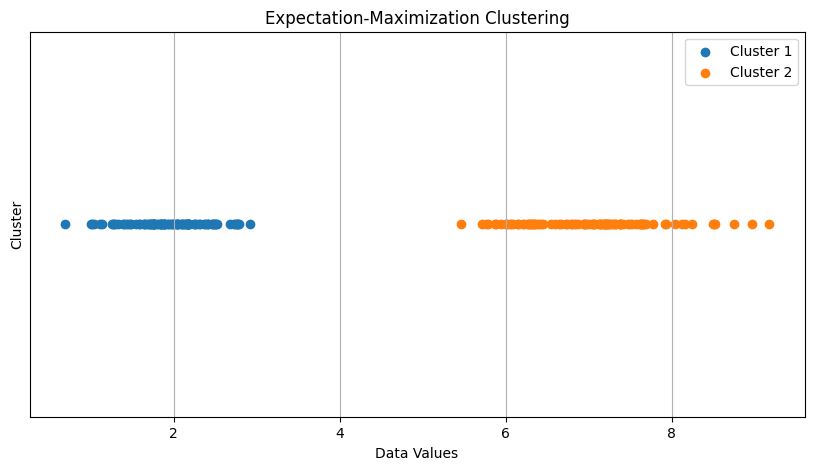

In [ ]:
# ---------------------------------------------------
# 10. EXPECTATION-MAXIMIZATION (EM) ALGORITHM
# ---------------------------------------------------

import numpy as np
import matplotlib.pyplot as plt

from sklearn.mixture import GaussianMixture


# ---------------------------------------------------
# STEP 1: Create Dataset
# ---------------------------------------------------

np.random.seed(42)

# First group
data1 = np.random.normal(
    loc=2,
    scale=0.5,
    size=100
)

# Second group
data2 = np.random.normal(
    loc=7,
    scale=0.8,
    size=100
)

# Combine both groups
X = np.concatenate([data1, data2])

# Convert to 2D
X = X.reshape(-1, 1)


# ---------------------------------------------------
# STEP 2: Create EM Model
# ---------------------------------------------------

model = GaussianMixture(
    n_components=2,
    random_state=42
)


# ---------------------------------------------------
# STEP 3: Apply EM Algorithm
# ---------------------------------------------------

model.fit(X)


# ---------------------------------------------------
# STEP 4: Predict Clusters
# ---------------------------------------------------

labels = model.predict(X)


# ---------------------------------------------------
# STEP 5: Display Cluster Means
# ---------------------------------------------------

print("Expectation-Maximization Algorithm")
print("-----------------------------------")

print("\nCluster Means:")

print(model.means_.flatten())


# ---------------------------------------------------
# STEP 6: Display Cluster Information
# ---------------------------------------------------

print("\nNumber of Data Points in Each Cluster:")

for i in range(2):

    count = np.sum(labels == i)

    print(
        "Cluster",
        i + 1,
        ":",
        count,
        "data points"
    )


# ---------------------------------------------------
# STEP 7: Plot Clusters
# ---------------------------------------------------

plt.figure(figsize=(10, 5))

plt.scatter(
    X[labels == 0],
    np.zeros(np.sum(labels == 0)),
    label="Cluster 1"
)

plt.scatter(
    X[labels == 1],
    np.zeros(np.sum(labels == 1)),
    label="Cluster 2"
)

plt.xlabel("Data Values")

plt.ylabel("Cluster")

plt.title("Expectation-Maximization Clustering")

plt.yticks([])

plt.legend()

plt.grid(True)

plt.show()